# Histograma e realce de contraste em fotos próprias

Três fotos minhas, cada uma com um problema de exposição diferente:

1. **escura demais**
2. **clara demais / lavada**
3. **bem exposta** (referência)

Para cada uma: conversão para tons de cinza, histograma, diagnóstico, **uma** operação de realce (expansão de contraste, equalização ou correção de gamma) com justificativa e parâmetro, e a figura de antes e depois com os dois histogramas.

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

plt.rcParams['figure.dpi'] = 110

## Funções (as mesmas da aula)

- `histograma`: contagem de pixels por nível de 0 a 255.
- `expandir_contraste(img, L, H)`: mapeia linearmente `[L, H]` para `[0, 255]`; o que está abaixo de L vira 0 e o que está acima de H vira 255.
- `equalizar`: `cv2.equalizeHist`, redistribui os níveis pela CDF para o histograma ficar o mais plano possível.
- `corrigir_gamma(img, gamma)`: `s = 255·(r/255)^γ` via tabela (`cv2.LUT`). γ < 1 clareia os tons escuros; γ > 1 escurece os tons claros.

In [2]:
def histograma(img):
    """Vetor com 256 posições: quantos pixels têm cada intensidade."""
    return cv2.calcHist([img], [0], None, [256], [0, 256]).ravel()


def expandir_contraste(img, L, H):
    """Expansão linear de contraste: [L, H] -> [0, 255]."""
    lut = np.clip((np.arange(256) - L) * 255.0 / (H - L), 0, 255).astype(np.uint8)
    return cv2.LUT(img, lut)


def equalizar(img):
    """Equalização de histograma (OpenCV)."""
    return cv2.equalizeHist(img)


def corrigir_gamma(img, gamma):
    """Correção de gamma: s = 255 * (r/255) ** gamma."""
    lut = np.clip(255.0 * (np.arange(256) / 255.0) ** gamma, 0, 255).astype(np.uint8)
    return cv2.LUT(img, lut)


def carregar_cinza(caminho, lado_max=800):
    """Lê a foto, converte para tons de cinza e reduz se for muito grande
    (fotos de celular têm muitos megapixels; o histograma não muda com isso)."""
    bgr = cv2.imread(caminho)
    assert bgr is not None, f'não encontrei {caminho}'
    cinza = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    escala = lado_max / max(cinza.shape)
    if escala < 1:
        cinza = cv2.resize(cinza, None, fx=escala, fy=escala, interpolation=cv2.INTER_AREA)
    return cinza


def resumo(img):
    """Números que ajudam a ler o histograma."""
    p1, p50, p99 = np.percentile(img, [1, 50, 99])
    print(f'média = {img.mean():.1f} | desvio = {img.std():.1f} | '
          f'p1 = {p1:.0f} | mediana = {p50:.0f} | p99 = {p99:.0f} | '
          f'min/max = {img.min()}/{img.max()}')
    print(f'pixels abaixo de 50: {(img < 50).mean():.0%} | acima de 200: {(img > 200).mean():.0%}')


def mostrar_histograma(img, titulo):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={'width_ratios': [1, 1.4]})
    ax[0].imshow(img, cmap='gray', vmin=0, vmax=255); ax[0].set_title(titulo); ax[0].axis('off')
    ax[1].bar(range(256), histograma(img), width=1, color='0.3')
    ax[1].set_xlim(-3, 258); ax[1].set_xlabel('intensidade'); ax[1].set_ylabel('nº de pixels')
    ax[1].set_title('Histograma')
    plt.tight_layout(); plt.show()


def antes_depois(antes, depois, rotulo):
    """Figura 2x2: imagens em cima, histogramas embaixo."""
    fig, ax = plt.subplots(2, 2, figsize=(11, 7), gridspec_kw={'height_ratios': [2.2, 1]})
    for c, (im, t) in enumerate([(antes, 'Antes'), (depois, f'Depois: {rotulo}')]):
        ax[0, c].imshow(im, cmap='gray', vmin=0, vmax=255); ax[0, c].set_title(t); ax[0, c].axis('off')
        ax[1, c].bar(range(256), histograma(im), width=1, color='0.3')
        ax[1, c].set_xlim(-3, 258); ax[1, c].set_xlabel('intensidade')
    ax[1, 0].set_ylabel('nº de pixels')
    plt.tight_layout(); plt.show()

## 1. Foto escura demais

Foto tirada com o celular no quarto com a luz apagada.

média = 0.9 | desvio = 1.8 | p1 = 0 | mediana = 0 | p99 = 9 | min/max = 0/20
pixels abaixo de 50: 100% | acima de 200: 0%


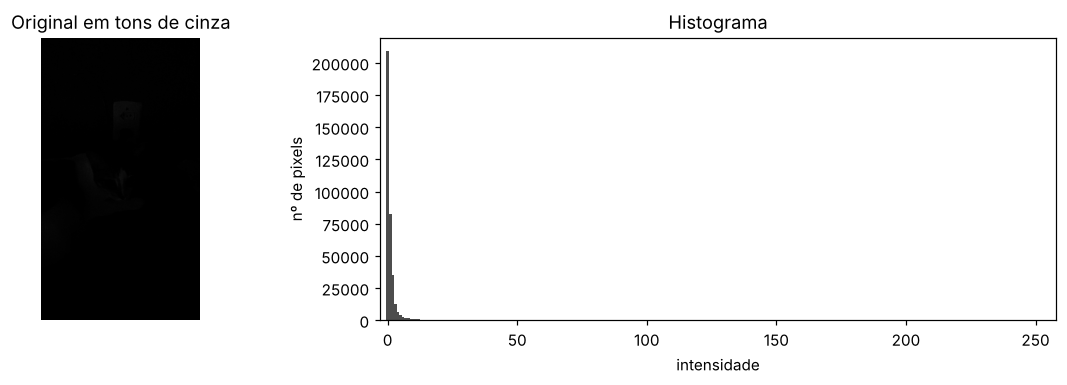

In [3]:
img_escura = carregar_cinza('fotos/escura.jpg')
resumo(img_escura)
mostrar_histograma(img_escura, 'Original em tons de cinza')

**Diagnóstico:** O histograma é praticamente uma única barra colada no zero: 58% dos pixels valem exatamente 0, 99,7% estão entre 0 e 12 e o valor máximo é só 20. A foto está extremamente subexposta e toda a informação da cena (a tomada e o gato deitado) está espremida em uns 12 níveis de cinza, numa faixa que o olho não consegue distinguir do preto.

**Operação escolhida: expansão de contraste** (L = 0, H = 12)

Como as intensidades ocupam uma faixa **estreitíssima** (0–12), a solução mais direta é esticar essa faixa linearmente para 0–255, multiplicando a escala por ~21. H = 12 deixa de fora só 0,3% dos pixels (os mais claros, que saturam em 255), e L = 0 porque a faixa já começa no preto. A correção de gamma precisaria de um γ muito pequeno (≈0,25) para chegar no mesmo brilho e levantaria junto o ruído do sensor no fundo. A equalização foi pior ainda nos testes: como há pouquíssimos níveis distintos, ela transforma cada um em saltos enormes e o resultado fica granulado e quase binário.

média = 19.1 | desvio = 36.1 | p1 = 0 | mediana = 0 | p99 = 191 | min/max = 0/255
pixels abaixo de 50: 91% | acima de 200: 1%


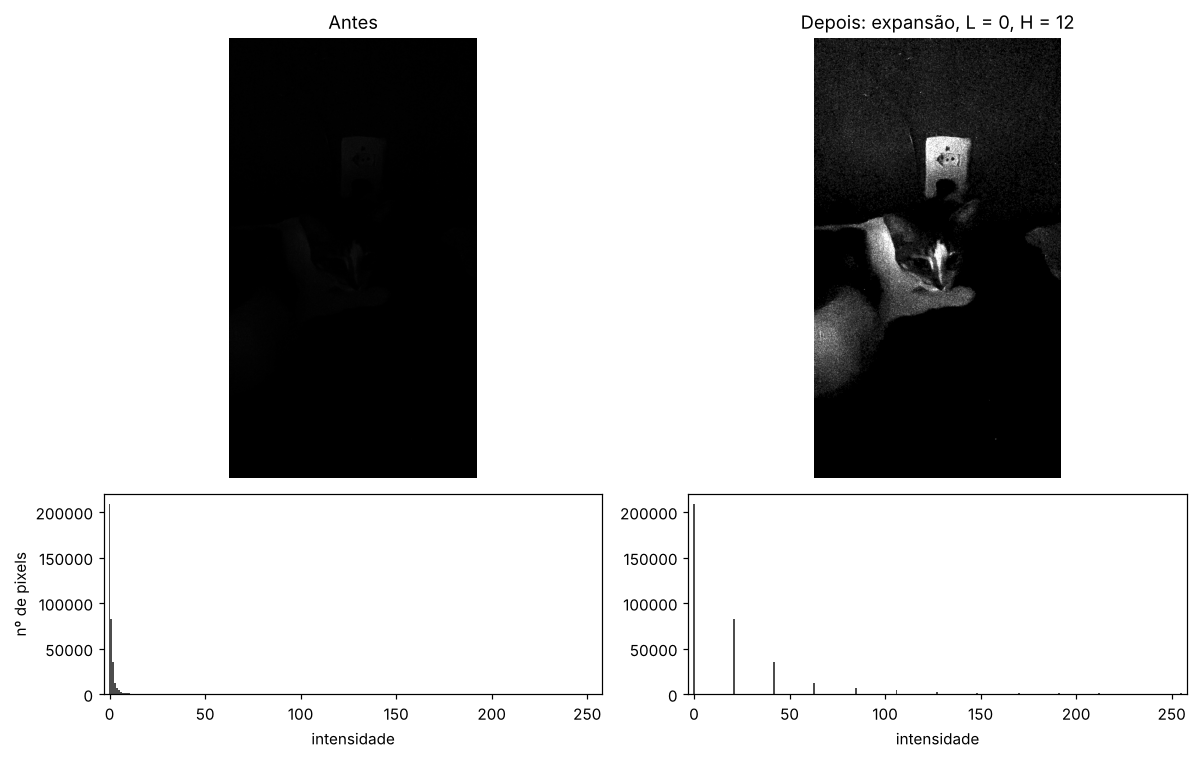

In [4]:
L, H = 0, 12
res_escura = expandir_contraste(img_escura, L, H)
resumo(res_escura)
antes_depois(img_escura, res_escura, 'expansão, L = 0, H = 12')

## 2. Foto clara demais / lavada

Print da tela de um documento em branco do Google Docs, com tema claro.

média = 249.8 | desvio = 11.2 | p1 = 195 | mediana = 250 | p99 = 255 | min/max = 0/255
pixels abaixo de 50: 0% | acima de 200: 99%


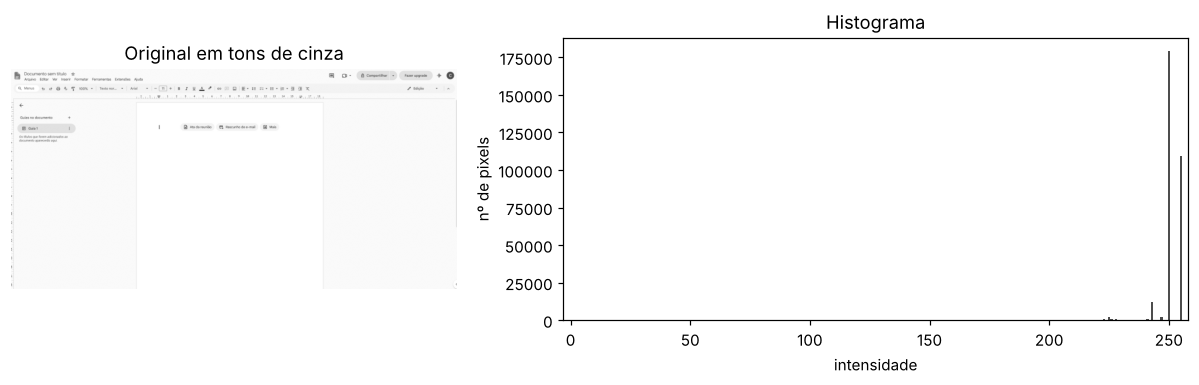

In [5]:
img_clara = carregar_cinza('fotos/clara.png')
resumo(img_clara)
mostrar_histograma(img_clara, 'Original em tons de cinza')

**Diagnóstico:** Quase tudo está no extremo direito do histograma: 99% dos pixels estão acima de 200, e só dois níveis concentram 91% da imagem (250, o cinza do fundo, com 57%, e 255, a folha branca, com 35%). A imagem está saturada no claro e com pouquíssimo contraste: a folha, o painel lateral e os botões são quase do mesmo tom e mal dá para separar uns dos outros.

**Operação escolhida: correção de gamma** (γ = 4)

Com γ > 1 a curva fica íngreme perto do branco, então os tons claros, onde está toda a imagem, são **afastados** uns dos outros: 250 vai para 235 e 243 vai para 210, enquanto o branco puro continua em 255. Assim, folha, fundo e botões passam a se diferenciar. Escolhi gamma em vez da expansão porque a expansão precisaria de L ≈ 195, e o 1% de pixels abaixo disso (justamente o texto e os ícones) seria todo jogado no preto; o gamma preserva a ordem e os detalhes desses tons escuros. A equalização foi descartada porque, com dois níveis dominando, ela deixa o fundo cinza-médio e a imagem bem artificial.

média = 236.7 | desvio = 26.9 | p1 = 87 | mediana = 235 | p99 = 255 | min/max = 0/255
pixels abaixo de 50: 1% | acima de 200: 96%


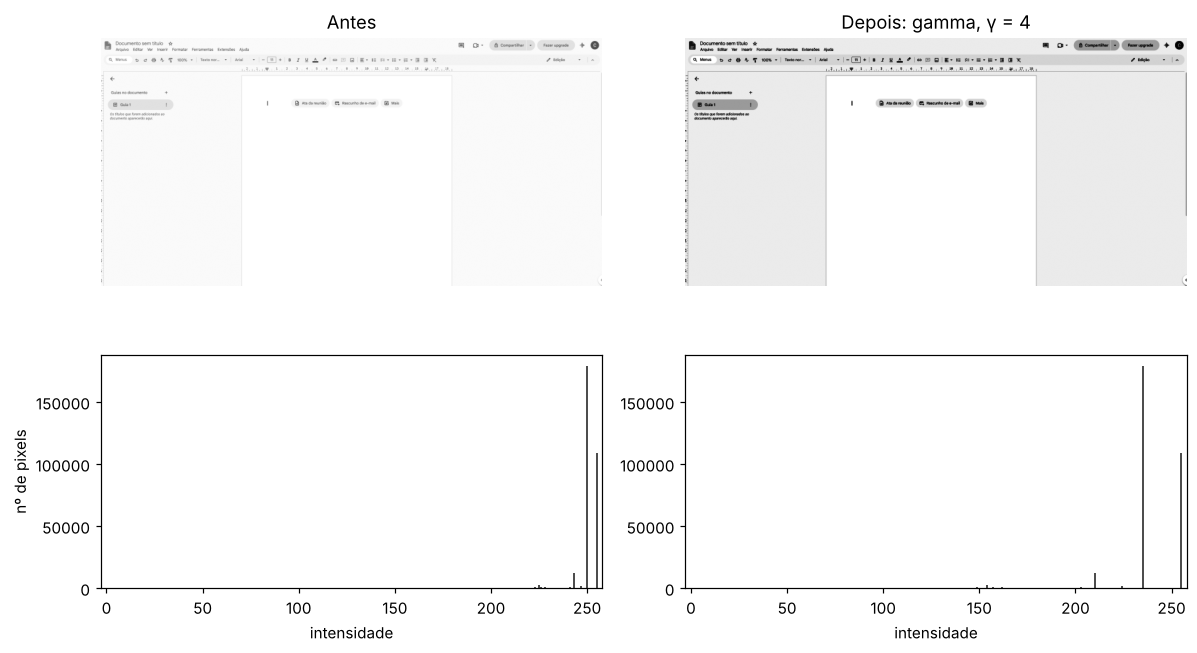

In [6]:
GAMMA = 4
res_clara = corrigir_gamma(img_clara, GAMMA)
resumo(res_clara)
antes_depois(img_clara, res_clara, 'gamma, γ = 4')

## 3. Foto bem exposta

Foto de um pôster com luz ambiente normal.

média = 121.1 | desvio = 59.9 | p1 = 13 | mediana = 114 | p99 = 243 | min/max = 4/251
pixels abaixo de 50: 12% | acima de 200: 12%


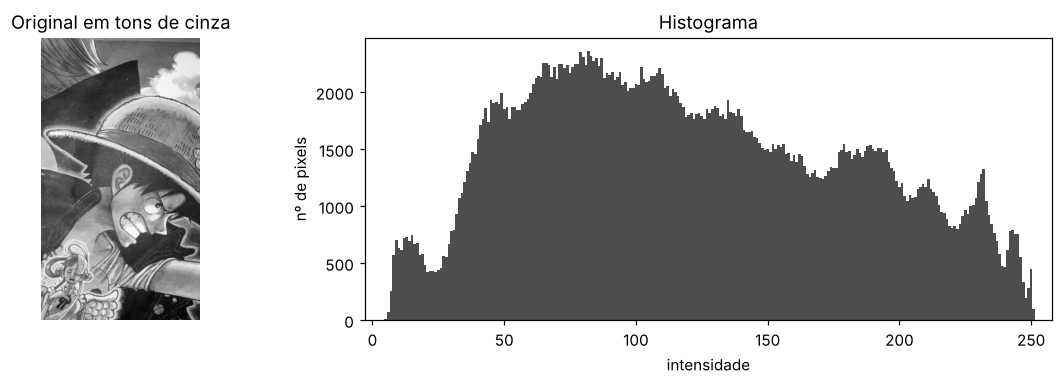

In [7]:
img_bem_exposta = carregar_cinza('fotos/bem_exposta.jpg')
resumo(img_bem_exposta)
mostrar_histograma(img_bem_exposta, 'Original em tons de cinza')

**Diagnóstico:** O histograma está espalhado por quase toda a escala, de 13 a 243 entre os percentis 1 e 99, com mediana 114 e desvio padrão alto (60), e não há acúmulo nem no preto nem no branco. A foto está bem exposta: tem sombras, tons médios e realces bem representados.

**Operação escolhida: expansão de contraste** (L = 13, H = 243)

Como não há defeito de exposição, a operação certa é a mais conservadora. Uma expansão linear com L e H nos percentis 1 e 99 só aproveita as pontas da escala que ainda sobravam (0–13 e 243–255), sem mudar a forma do histograma. A equalização mexeria na distribuição de tons de uma foto que já está boa, e o gamma clarearia ou escureceria tudo sem motivo.

média = 119.3 | desvio = 66.3 | p1 = 0 | mediana = 111 | p99 = 255 | min/max = 0/255
pixels abaixo de 50: 17% | acima de 200: 15%


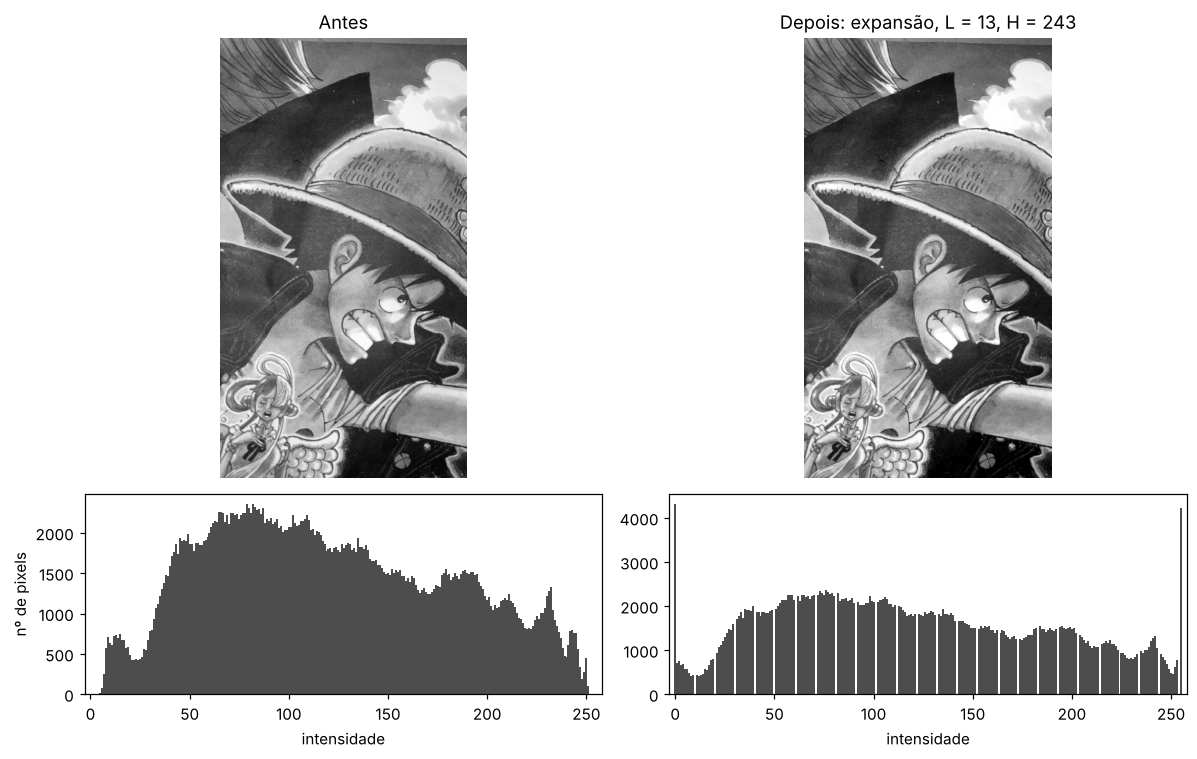

In [8]:
L, H = 13, 243
res_bem_exposta = expandir_contraste(img_bem_exposta, L, H)
resumo(res_bem_exposta)
antes_depois(img_bem_exposta, res_bem_exposta, 'expansão, L = 13, H = 243')

## Quanto cada operação mudou a imagem

Para apoiar a resposta final, meço a diferença média absoluta entre antes e depois (em níveis de cinza) e quanto o desvio padrão, que serve de medida de contraste, mudou.

In [9]:
for nome, a, d in [('escura', img_escura, res_escura),
                   ('clara', img_clara, res_clara),
                   ('bem exposta', img_bem_exposta, res_bem_exposta)]:
    dif = np.abs(a.astype(int) - d.astype(int)).mean()
    print(f'{nome:12s} diferença média = {dif:5.1f} níveis | desvio: {a.std():5.1f} -> {d.std():5.1f}')

escura       diferença média =  18.1 níveis | desvio:   1.8 ->  36.1
clara        diferença média =  13.1 níveis | desvio:  11.2 ->  26.9
bem exposta  diferença média =   5.7 níveis | desvio:  59.9 ->  66.3


## Em qual das três imagens a operação fez menos diferença? Por quê?

A operação fez menos diferença na foto bem exposta (a do pôster): os pixels mudaram em média menos de 6 níveis de cinza, contra cerca de 13 no print e 18 na foto escura, e visualmente as duas versões são quase iguais. Isso acontece porque o histograma dela já ocupava praticamente toda a faixa de 0 a 255, então a expansão de contraste quase não tinha para onde esticar: com L = 13 e H = 243 a curva de mapeamento fica muito próxima da identidade. Nas outras duas, as intensidades estavam concentradas numa parte pequena da escala (abaixo de 12 na foto escura, acima de 240 no print), e a operação redistribuiu esses tons por uma faixa bem maior, revelando o gato e a tomada que estavam invisíveis no escuro e separando a folha, o fundo e os botões no print. Essas operações corrigem um mau uso da faixa dinâmica, e quando a imagem já a usa bem, sobra pouco a corrigir.